# Unconfoundedness vs Parallel Trends

**Which assumption fits your self-selected treatment?**

This notebook accompanies the article of the same name. It simulates a weekly user panel where users opt into a treatment, then estimates the effect two ways:

- **Unconfoundedness**: compare treated and control users who had the same history up to the week before treatment.
- **Parallel trends**: compare the change in engagement for treated users with the change for controls.

Both are estimated with double machine learning. The estimator is the same. Only the assumption changes, and each one wins under a different selection mechanism.

Sections follow the article. Everything runs from `src/uvpt`, so each diagnostic can be pointed at your own panel.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from uvpt import scenario_config, simulate
from uvpt.diagnostics import (
    att_weights,
    balance_table,
    diagnose,
    event_time_means,
    fit_propensity,
    placebo_event_time,
    placebo_test,
    pretrend_event_time,
    propensity_features,
    sensitivity,
)
from uvpt.estimators import dml_did, dml_unconf, estimate_all
from uvpt.features import did_design, to_wide, unconf_design
from uvpt.montecarlo import load, rejection_rates, summarise
from uvpt.plots import (
    plot_balance,
    plot_estimates,
    plot_event_means,
    plot_gaps,
    plot_mc,
    plot_overlap,
    use_style,
)

use_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)

SEED = 1
N_USERS = 10_000
SCENARIOS = {
    "a": "a. Observables only",
    "b": "b. Stable trait",
    "c": "c. Transitory dip",
    "d": "d. Both",
}
ASSETS = "../assets"

In [2]:
sims = {s: simulate(scenario_config(s, n_users=N_USERS, seed=SEED)) for s in SCENARIOS}
wides = {s: to_wide(r.panel) for s, r in sims.items()}
truth = {s: r.true_att() for s, r in sims.items()}

sims["a"].panel.head()

,user_id,event_time,week,treated,y,x1,x2,x3
0,0,-8,2,0,42.899,0.346,0.0,1.649
1,0,-7,3,0,41.953,0.346,0.0,1.649
2,0,-6,4,0,45.980,0.346,0.0,1.649
3,0,-5,5,0,45.934,0.346,0.0,1.649
4,0,-4,6,0,48.625,0.346,0.0,1.649


The panel has one row per user and event time, from t-8 to t+4 around each user's index week. Treated users took the treatment in their index week. Controls are users who were eligible that week and did not take it. Both groups must be active in each of the four weeks before index.

`to_wide` turns it into one row per user, with outcome columns named by event time (`y_m8` is t-8, `y_p0` is t0).

## 1. Which would you pick?

A product team launches an opt-in feature. Users choose whether to turn it on. The team wants the effect on weekly engagement among users who turned it on (the ATT).

Two analysts get the same data.

- **Analyst A** learned causal inference from the ML side: *Causal Inference for the Brave and True*, EconML, DoubleML. She conditions on each user's last eight weeks of engagement and fits a doubly robust DML model.
- **Analyst B** learned it from econometrics: *The Mixtape*, event studies. He runs a conditional difference-in-differences, also with DML.

Here are their answers on scenario c.

In [3]:
hook = estimate_all(wides["c"]).set_index("method")
hook.loc[["unconf", "did"], ["estimate", "ci_low", "ci_high"]].rename(
    index={"unconf": "Analyst A (unconfoundedness)", "did": "Analyst B (DiD)"}
)

,estimate,ci_low,ci_high
method,,,
Analyst A (unconfoundedness),2.127,1.874,2.380
Analyst B (DiD),3.064,2.832,3.296


In [4]:
print(f"True ATT: {truth['c']:.2f}")

True ATT: 2.00


Both estimates are tight and they do not overlap. Both analysts used a sound estimator, so the estimator is not the problem. They made different identifying assumptions, and only one of them holds in this data.

In scenario c, Analyst A is right. In scenario b, Analyst B is. The rest of this notebook shows why, and how to tell from the data which one you are in.

## 2. Two assumptions, two failure modes

Write the post-period outcome as

$$Y_{\text{post}} = \alpha + \tau D + \beta\, Y_{\text{pre}} + \gamma' X + \varepsilon.$$

- **DiD** fixes $\beta = 1$. It subtracts each user's full pre-period level, so anything stable within a user cancels.
- **Unconfoundedness** estimates $\beta$ from the data. Under mean reversion $\beta < 1$, so only part of a low pre-period carries forward.

Each design fails where its $\beta$ is wrong:

- **Stable unobserved trait.** A trait that raises engagement every week acts like $\beta = 1$. DiD removes it. Conditioning on lagged outcomes only removes the part the lags reveal, so unconfoundedness is biased.
- **Selection on a transitory dip.** Users who just had a bad few weeks are more likely to opt in, and would have bounced back anyway. The true $\beta$ is below 1. DiD credits the rebound to the treatment and overstates the effect (the Ashenfelter dip).

The simulator has four scenarios. Selection is negative in all of them: low-trait users and users with low recent engagement are more likely to opt in.

| Scenario | Selection on | Unconfoundedness | Parallel trends |
|---|---|---|---|
| a | observed covariates | holds | holds |
| b | covariates and a stable trait | fails | holds |
| c | covariates and engagement over t-3 to t-1 | holds | fails |
| d | all of the above | fails | fails |

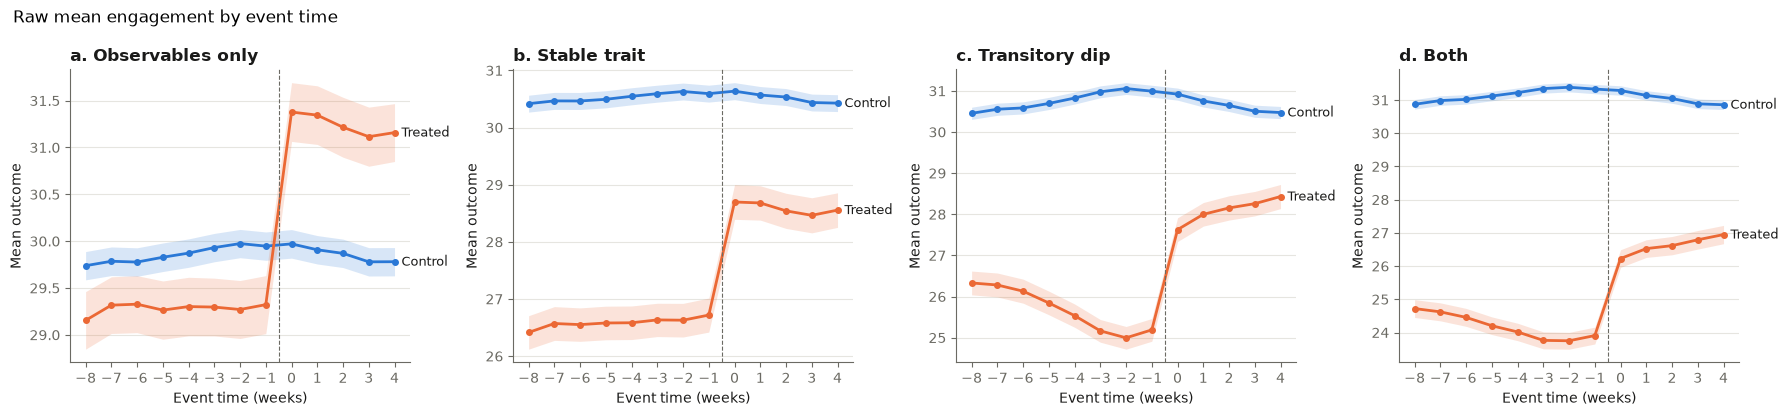

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (s, title) in zip(axes, SCENARIOS.items()):
    plot_event_means(event_time_means(wides[s]), ax=ax, title=title)
fig.suptitle("Raw mean engagement by event time", x=0.01, ha="left")
fig.tight_layout()

The raw means already hint at the mechanism. In b the treated sit lower throughout and run parallel to controls. In c and d the treated dip into the index week. Raw means mix all of this with the effect of the observed covariates, so the next sections adjust for those.

In [6]:
single = []
for s in SCENARIOS:
    t = estimate_all(wides[s]).assign(scenario=s, truth=truth[s])
    single.append(t)
single = pd.concat(single, ignore_index=True)
single["bias"] = single["estimate"] - single["truth"]
single.pivot(index="scenario", columns="method", values="bias")[
    ["naive_unconf", "unconf", "did", "did_lags"]
]

method,naive_unconf,unconf,did,did_lags
scenario,,,,
a,-0.618,1.646e-04,-0.046,0.002
b,-3.949,-6.558e-01,0.079,-0.623
c,-4.698,1.274e-01,1.064,0.327
d,-6.548,-3.459e-01,0.951,-0.133


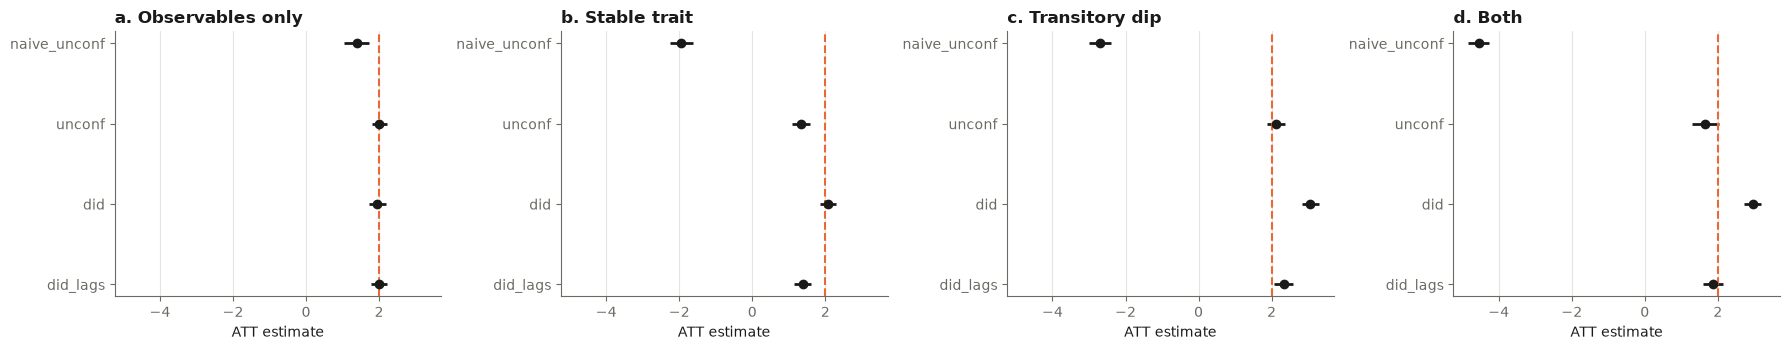

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharex=True)
order = ["naive_unconf", "unconf", "did", "did_lags"]
for ax, (s, title) in zip(axes, SCENARIOS.items()):
    plot_estimates(single[single["scenario"] == s], truth=truth[s], ax=ax, title=title, order=order)
fig.tight_layout()

One draw per scenario, true effect 2.0:

- **a**: both DML designs land on the truth. The naive comparison does not, because selection on observed covariates still biases it.
- **b**: DiD is right. Unconfoundedness understates the effect.
- **c**: unconfoundedness is right. DiD overstates it.
- **d**: the two DML estimates sit either side of the truth. This is the Angrist and Pischke bracketing result.

Section 8 repeats this over 200 draws.

## 3. Why "just switch to DiD" fails for churn

A common reaction to section 2 is to use DiD whenever selection worries you. For churn that does not work.

Churn is absorbing: once a user churns they stay churned. To be eligible for treatment a user has to be active before the index week. So pre-period churn is zero for every treated and control user, by construction.

- The pre-trend check has nothing to test. Both groups are flat at zero.
- DiD collapses to a post-period comparison of churn rates. That is the naive estimator with no adjustment for who opted in.
- Conditioning on being active up to the index week is a survivorship filter. Users who would have churned earlier never make it into either group, and the filter treats the two groups differently when selection depends on recent engagement.

For churn the identification has to come from conditioning on the pre-period history: unconfoundedness with lagged engagement, or a survival model with time-varying covariates. This repo uses weekly engagement, a non-absorbing outcome, so both designs can be compared on the same data.

## 4. Lagged outcomes vs DiD covariate rules

The two designs need different covariates.

- **Unconfoundedness**: condition on the outcome history. Here that is engagement at t-8 to t-1, its slope and the recent change, plus non-outcome covariates.
- **DiD**: use non-outcome covariates measured before the pre-window. Do not add outcome lags. Matching on pre-period outcomes in a DiD induces regression to the mean when the groups differ in levels (Daw and Hatfield 2018).

Both designs here also get index-week seasonality. It is not an outcome and it is fixed before the pre-window.

The `did_lags` variant adds engagement at t-8 to t-5 to the DiD covariates.

In [8]:
single.pivot(index="scenario", columns="method", values="bias")[["did", "did_lags"]]

method,did,did_lags
scenario,,
a,-0.046,0.002
b,0.079,-0.623
c,1.064,0.327
d,0.951,-0.133


- In **b** parallel trends holds without the lags. Adding them breaks it: `did_lags` is about as biased as the unconfoundedness design. Treated users have a lower trait, so matching them to controls with the same early engagement picks controls with a higher trait and a temporarily low shock, which then reverts.
- In **c** the lags help. They carry part of the dip that drives selection. They do not carry all of it, so some bias remains.

So adding lags to a DiD is not a neutral robustness check. It changes the identifying assumption, and the change helps or hurts depending on the selection mechanism.

## 5. The diagnostic: event-time plots, balance vs placebo

### 5.1 Balance is mechanical

The usual first check is covariate balance after weighting. Fit the propensity on features through t-1 and weight controls by $p / (1 - p)$.

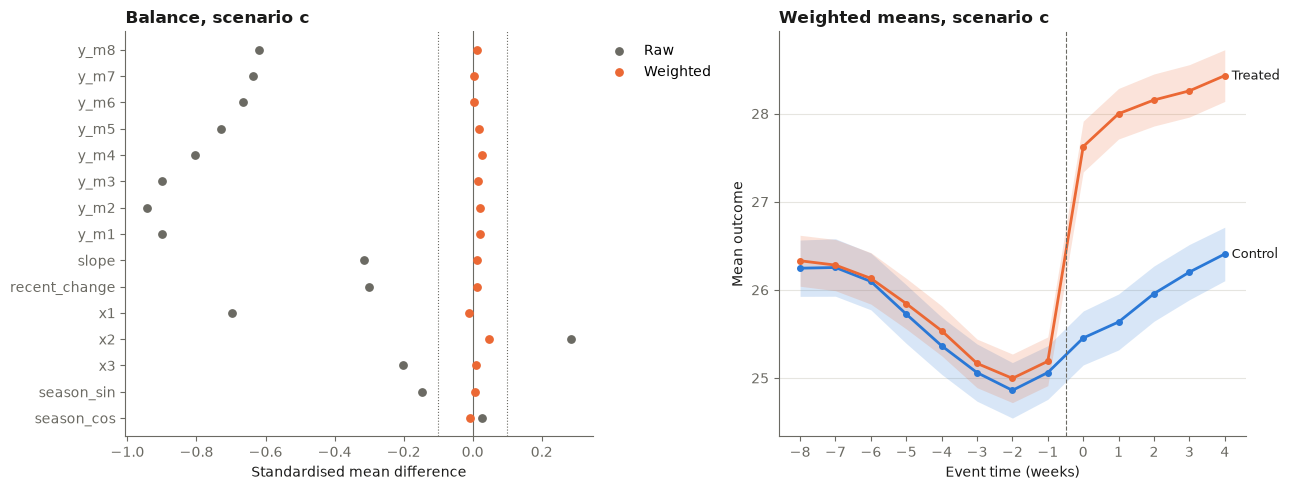

In [9]:
x_c = propensity_features(wides["c"], cutoff=-1)
ps_c = fit_propensity(x_c, wides["c"]["treated"])
w_c = att_weights(ps_c, wides["c"]["treated"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_balance(balance_table(x_c, wides["c"]["treated"], w_c), ax=axes[0], title="Balance, scenario c")
plot_event_means(event_time_means(wides["c"], w_c), ax=axes[1], title="Weighted means, scenario c")
fig.tight_layout()

Weighted balance is near perfect and the weighted pre-period lines lie on top of each other. That is true in every scenario, including the ones where the design is biased. The weights were fitted to balance exactly these features, so balance on them cannot test anything.

A real test has to look at something the propensity model did not see.

### 5.2 The DiD check: pre-trends on changes

Weight controls on non-outcome covariates only, as the DiD design does. Express each user's engagement relative to their own mean over t-8 to t-5, so stable level differences drop out. Under parallel trends the treated minus control gap is zero over t-4 to t-1.

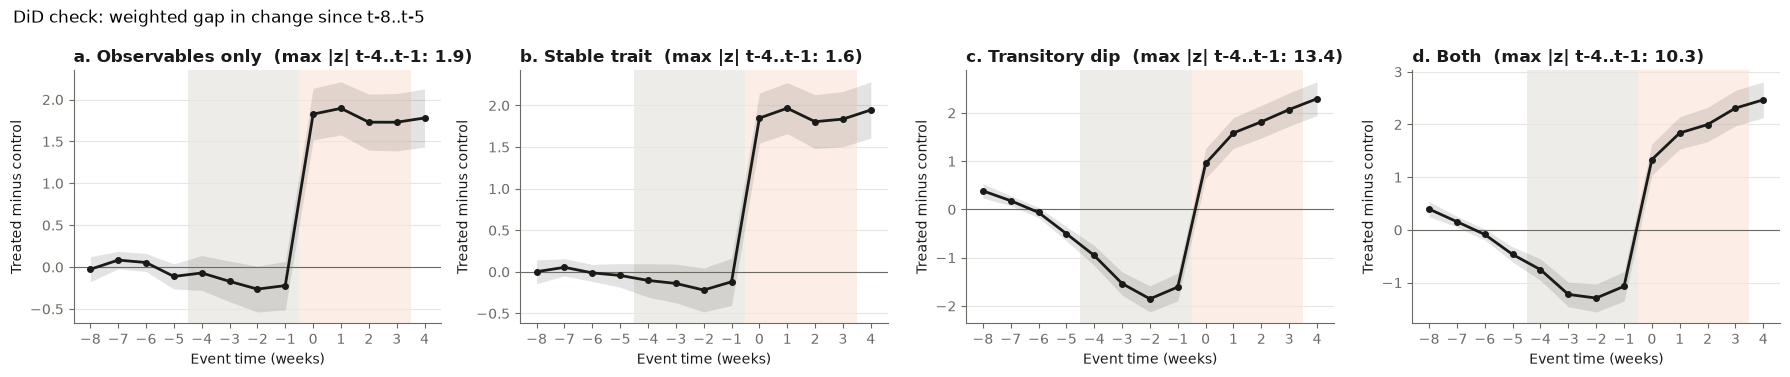

In [10]:
pretrends = {s: pretrend_event_time(w) for s, w in wides.items()}

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, (s, title) in zip(axes, SCENARIOS.items()):
    p = pretrends[s]
    plot_gaps(p["gaps"], ax=ax, title=f"{title}  (max |z| t-4..t-1: {p['pretrend_max_abs_z']:.1f})")
    ax.title.set_fontsize(10)
fig.suptitle("DiD check: weighted gap in change since t-8..t-5", x=0.01, ha="left")
fig.tight_layout()

Flat in a and b. A clear dip in c and d, starting about t-6 and deepest at t-2. Parallel trends fails exactly where DiD was biased.

### 5.3 The unconfoundedness check: placebo on history through t-5

Fit the propensity on the outcome history through t-5 only, then look at t-4 to t-1. Nothing has been treated yet, so any gap is a failure of selection on the observed history.

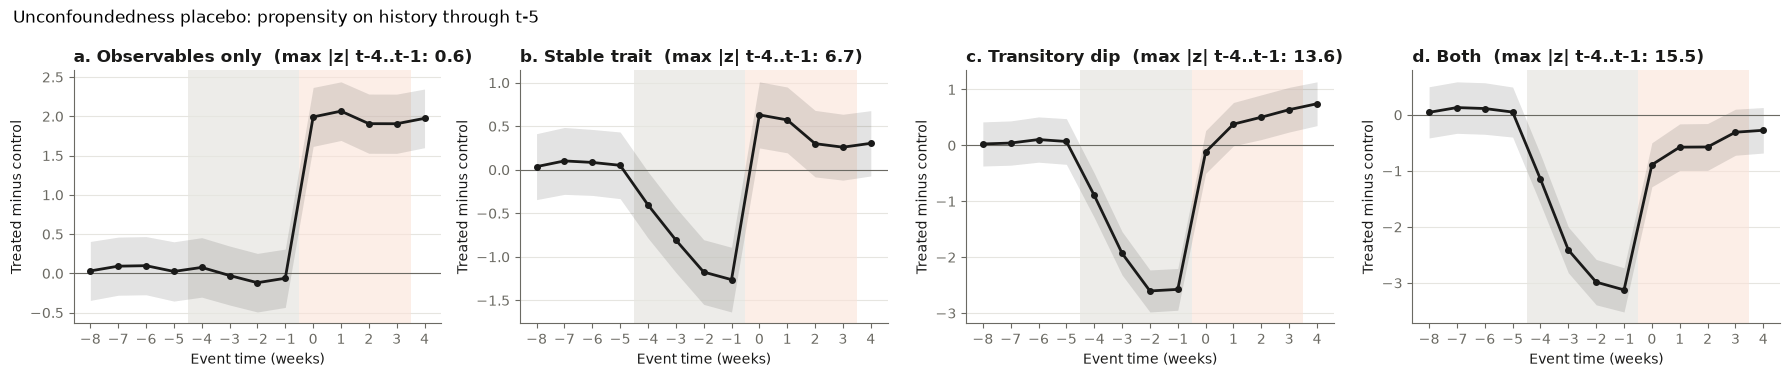

In [11]:
placebos = {s: placebo_event_time(w) for s, w in wides.items()}

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, (s, title) in zip(axes, SCENARIOS.items()):
    p = placebos[s]
    plot_gaps(p["gaps"], ax=ax, title=f"{title}  (max |z| t-4..t-1: {p['placebo_max_abs_z']:.1f})")
    ax.title.set_fontsize(10)
fig.suptitle("Unconfoundedness placebo: propensity on history through t-5", x=0.01, ha="left")
fig.tight_layout()

- **a**: flat.
- **b**: the gap drifts down. Matching on four noisy early weeks leaves a trait difference that keeps showing up. This is the signature of an unobserved stable trait.
- **c** and **d**: a sharp dip. Here the placebo also fails in c, where unconfoundedness is valid at t0.

The last point matters. In c, selection runs on engagement at t-3 to t-1. A placebo that stops at t-5 drops exactly those weeks. No pre-period check can separate "selection on recent engagement" (c) from "recent engagement plus a stable trait" (d). That is why the decision rule in section 6 ends with bounds.

In [12]:
placebo_dml = pd.concat(
    [placebo_test(w).assign(scenario=s) for s, w in wides.items()], ignore_index=True
)
placebo_dml.pivot(index="scenario", columns="method", values=["estimate", "rejects_zero"])

estimate                rejects_zero               
method   did_placebo unconf_placebo  did_placebo unconf_placebo
scenario                                                       
a             -0.164         -0.058        False          False
b             -0.151         -0.978        False           True
c              -1.49         -2.052         True           True
d             -1.093         -2.452         True           True

The same checks as DML estimates on the placebo window, with a true value of zero. The DiD placebo rejects in c and d only. The unconfoundedness placebo rejects in b, c and d.

### 5.4 Overlap

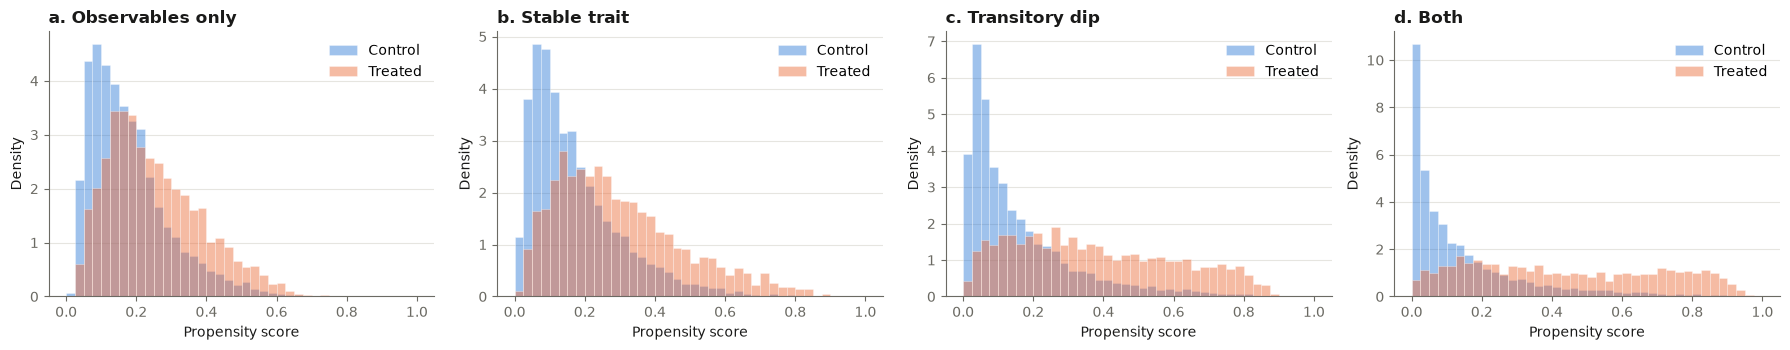

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, (s, title) in zip(axes, SCENARIOS.items()):
    x = propensity_features(wides[s], cutoff=-1)
    ps = fit_propensity(x, wides[s]["treated"])
    plot_overlap(ps, wides[s]["treated"], ax=ax, title=title)
fig.tight_layout()

Overlap is good in a and b. In c and d some treated users reach propensities near 0.9, where few controls sit. Those few controls carry large weights, and the effective sample size of the control weights falls from about 3,500 in a to about 700 in d (section 7). Nothing is clipped at 0.01 here. With stronger selection, clipping and a check on the largest weights would matter.

## 6. Decision rule

| DiD pre-trend check | Unconfoundedness placebo | Reading |
|---|---|---|
| flat | flat | Both plausible. They should agree. |
| flat | drifts | Stable unobserved trait. Use DiD. |
| dips | flat or dips | Parallel trends fails. Use unconfoundedness with lags and report DiD as the other bound. |

A check flags when any week in t-4 to t-1 has $|z| > 2.5$ (5% with a Bonferroni correction over four weeks). `diagnose` runs both checks and returns the reading.

In [14]:
for s, w in wides.items():
    out = diagnose(w)
    print(f"{SCENARIOS[s]:<22} pre-trend flag: {out['pretrend_flag']!s:<5}  placebo flag: {out['placebo_flag']!s:<5}")
    print(f"  {out['reading']}\n")

a. Observables only    pre-trend flag: False  placebo flag: False
  No pre-period divergence in either check. Both designs are plausible and their estimates should agree.



b. Stable trait        pre-trend flag: False  placebo flag: True 
  Pre-trends are flat but the unconfoundedness placebo drifts. This is the signature of a stable unobserved trait: prefer DiD.



c. Transitory dip      pre-trend flag: True   placebo flag: True 
  Pre-trends diverge, so parallel trends fails. The unconfoundedness placebo cannot tell selection on recent outcomes from a stable trait. Prefer unconfoundedness if selection plausibly runs on recent engagement, and report both estimates as bounds.



d. Both                pre-trend flag: True   placebo flag: True 
  Pre-trends diverge, so parallel trends fails. The unconfoundedness placebo cannot tell selection on recent outcomes from a stable trait. Prefer unconfoundedness if selection plausibly runs on recent engagement, and report both estimates as bounds.



On your own data, build a long panel with one row per user and event time and call:

```python
wide = to_wide(panel, user="user_id", time="event_time", treated="treated",
               outcome="sessions", covariates=["tenure", "platform"], week="week")
out = diagnose(wide)
print(out["reading"])
```

The event time window, the pre and post windows and the placebo cutoff all have arguments.

## 7. Estimation: DML for either design

Both designs use the same machinery:

- **Unconfoundedness**: `DoubleMLIRM` with the ATTE score.
- **DiD**: `DoubleMLDIDBinary` on a two-period panel (pre-window mean and post-window mean), the Sant'Anna and Zhao doubly robust DiD.

Both use LightGBM nuisances, 5-fold cross-fitting and propensities clipped at 0.01. The choice of estimator is separate from the choice of design. A flexible estimator cannot rescue an assumption that does not hold.

In [15]:
overlap_cols = ["overlap_ess_controls", "overlap_share_clipped", "overlap_max_weight_share"]
single[single["method"].isin(["unconf", "did"])].pivot(
    index="scenario", columns="method", values=overlap_cols
)

overlap_ess_controls           overlap_share_clipped        overlap_max_weight_share       
method                    did    unconf                   did unconf                      did unconf
scenario                                                                                            
a                    3546.509  3505.517                   0.0    0.0                    0.002  0.002
b                    3981.863  1907.308                   0.0    0.0                    0.002  0.007
c                    3220.859  1337.125                   0.0    0.0                    0.002  0.006
d                    3732.443   686.489                   0.0    0.0                    0.003  0.013

No controls are clipped in any scenario. The effective sample size of the control weights is lowest for unconfoundedness in d, where selection on observed history is strongest.

### Sensitivity

DoubleML bounds the estimate under an unobserved confounder that explains a share `cf_y` of the residual outcome variation and `cf_d` of the residual treatment variation. The robustness value `rv` is the strength at which the bounds reach zero.

In [16]:
rows = []
for s in ["a", "b", "c"]:
    w = wides[s]
    for est in (dml_unconf(unconf_design(w)), dml_did(did_design(w))):
        rows.append({"scenario": s, **sensitivity(est, cf_y=0.03, cf_d=0.03)})
pd.DataFrame(rows).set_index(["scenario", "method"])

estimate  theta_lower  theta_upper  ci_lower  ci_upper     rv    rva
scenario method                                                                      
a        unconf     2.000        1.725        2.275     1.554     2.446  0.198  0.182
         did        1.954        1.633        2.276     1.440     2.469  0.169  0.153
b        unconf     1.344        1.091        1.598     0.894     1.815  0.149  0.127
         did        2.079        1.761        2.397     1.571     2.587  0.180  0.165
c        unconf     2.127        1.828        2.427     1.618     2.647  0.194  0.171
         did        3.064        2.737        3.390     2.542     3.585  0.248  0.232

The sensitivity bounds are useful for reporting. They do not choose the design.

- In b the biased unconfoundedness estimate has a robustness value of 0.15. The valid DiD estimate has 0.18.
- In c the biased DiD estimate has the highest robustness value in the table (0.25). The valid unconfoundedness estimate has 0.19.

Sensitivity analysis asks how strong a hidden confounder would need to be to move an estimate. It cannot say whether the design's assumption holds. The pre-period checks in section 5 do that.

## 8. Simulation results

200 replications per scenario, 10k users each, true ATT 2.0. LightGBM with 150 trees for the nuisances. Each replication also runs both placebo checks. The results are in `results/` and can be regenerated with `tools/run_montecarlo.py`.

In [17]:
mc = load("../results")
est = mc[~mc["method"].isin(["pretrend_gap", "unconf_placebo", "did_placebo"])]
summary = summarise(est)
summary.pivot(index="scenario", columns="method", values=["bias", "rmse", "coverage"])[
    [(m, k) for m in ["bias", "rmse", "coverage"] for k in ["naive_unconf", "unconf", "did", "did_lags"]]
]

bias                                rmse                            coverage                      
method   naive_unconf unconf    did did_lags naive_unconf unconf    did did_lags naive_unconf unconf   did did_lags
scenario                                                                                                           
a              -0.609  0.007  0.003    0.004        0.629  0.099  0.117    0.109        0.035  0.935  0.93    0.945
b              -3.811 -0.702  0.001   -0.675        3.815  0.709  0.115    0.684        0.000  0.000  0.94    0.000
c              -4.734 -0.015  1.011    0.235        4.736  0.116  1.016    0.260        0.000  0.935  0.00    0.495
d              -6.533 -0.730  0.813   -0.390        6.535  0.743  0.820    0.410        0.000  0.005  0.00    0.130

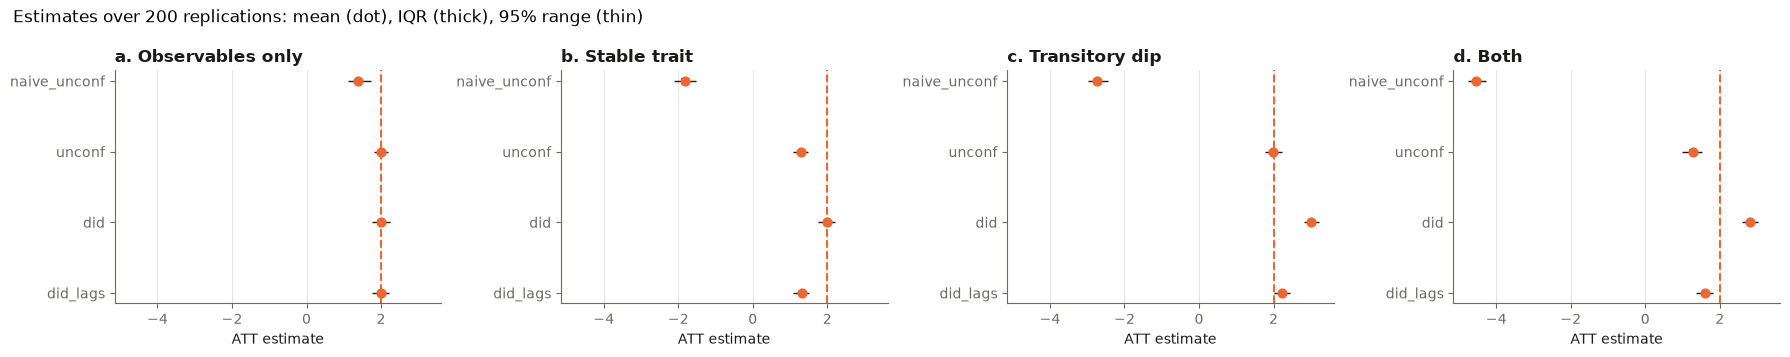

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharex=True)
for ax, (s, title) in zip(axes, SCENARIOS.items()):
    plot_mc(est, s, ax=ax, title=title, order=["naive_unconf", "unconf", "did", "did_lags"])
fig.suptitle("Estimates over 200 replications: mean (dot), IQR (thick), 95% range (thin)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(f"{ASSETS}/mc_results.png", dpi=150, bbox_inches="tight")

In [19]:
d = est[est["scenario"] == "d"].pivot(index="rep", columns="method", values="estimate")
t = est[est["scenario"] == "d"].groupby("rep")["truth"].first()
lo, hi = d[["unconf", "did"]].min(axis=1), d[["unconf", "did"]].max(axis=1)
print(f"Scenario d: truth between the two DML estimates in {((lo < t) & (t < hi)).mean():.0%} of replications")

Scenario d: truth between the two DML estimates in 100% of replications


In [20]:
rejection_rates(mc).loc[:, ["pretrend_gap", "did_placebo", "unconf_placebo"]]

,pretrend_gap,did_placebo,unconf_placebo
scenario,,,
a,0.03,0.04,0.03
b,0.03,0.03,1.00
c,1.00,1.00,1.00
d,1.00,1.00,1.00


Over 200 replications per scenario:

- **Where an assumption holds, its design is unbiased** (|bias| at most 0.02) with coverage of 93% to 95%.
- **Where it fails, coverage collapses.** Unconfoundedness in b has bias -0.70 and 0% coverage. DiD in c has bias +1.01 and 0% coverage. The intervals stay narrow, so a biased design gives a confident wrong answer.
- **DiD with lags** matches unconfoundedness in b (-0.68) and cuts the DiD bias in c to +0.24, with 50% coverage.
- **Bracketing.** In d the two designs err in opposite directions (-0.73 and +0.81). The truth sits between them in every replication.
- **The checks.** The DiD pre-trend check flags 3% of replications in a and b and all of them in c and d. The unconfoundedness placebo flags all replications in b, c and d.

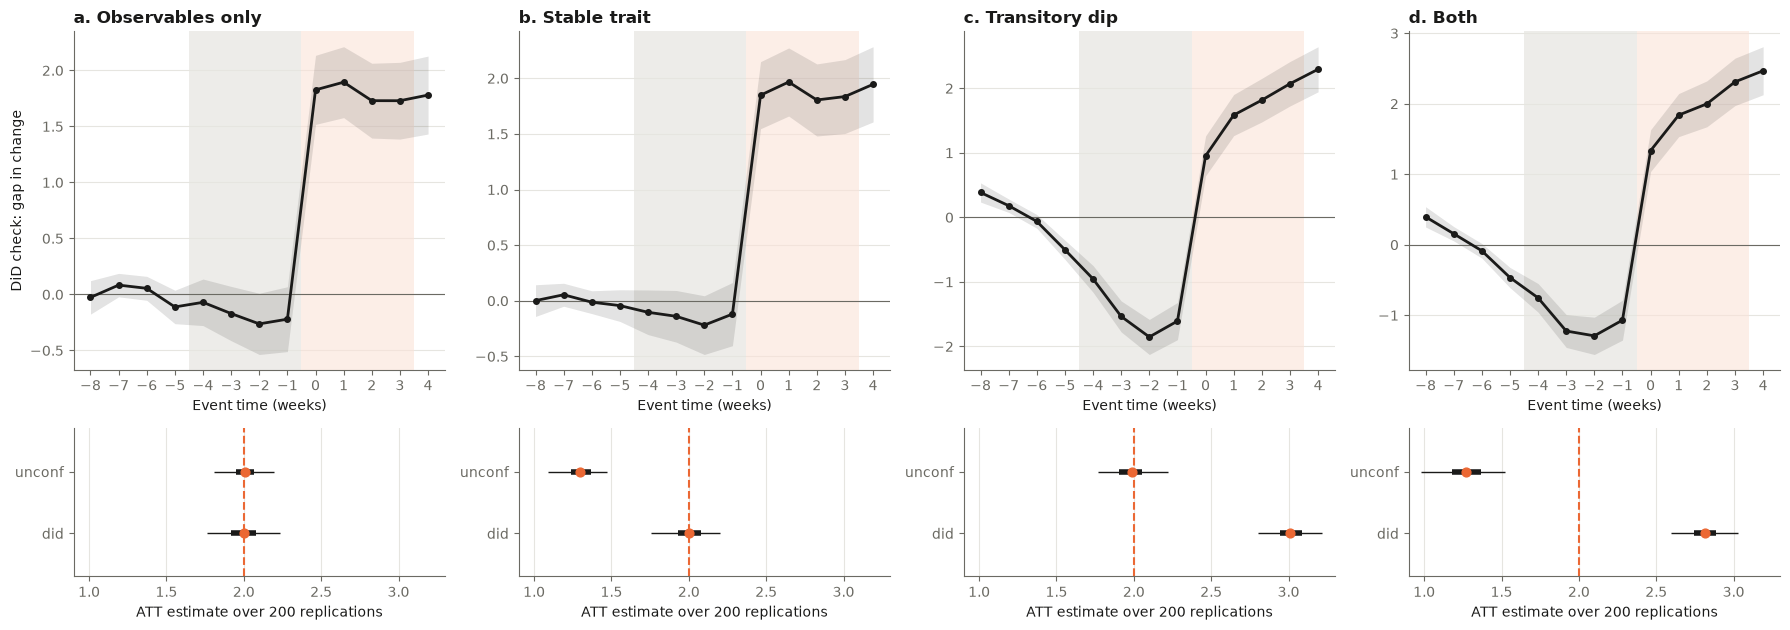

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(18, 6.4), gridspec_kw={"height_ratios": [1.6, 0.7]})
for j, (s, title) in enumerate(SCENARIOS.items()):
    plot_gaps(pretrends[s]["gaps"], ax=axes[0, j], title=title)
    axes[0, j].set_ylabel("DiD check: gap in change" if j == 0 else "")
    plot_mc(est, s, ax=axes[1, j], order=["unconf", "did"])
    axes[1, j].set_xlim(0.9, 3.3)
    axes[1, j].set_ylim(-0.7, 1.7)
    axes[1, j].set_xlabel("ATT estimate over 200 replications")
fig.tight_layout()
fig.savefig(f"{ASSETS}/hero.png", dpi=150, bbox_inches="tight")

The figure above is the README preview: the DiD pre-trend check on top, the Monte Carlo spread of both designs below.